# Power BI Desktop Fundamentals

**Power BI Desktop** is Microsoft's free BI authoring tool (Windows). It has three layers: **Power Query** (load and transform data, language *M*), the **data model** (tables and relationships, usually a star schema), and **DAX** (Data Analysis Expressions) for measures. Publishing and sharing need a Power BI service licence; building reports in Desktop is free.

Like Tableau, Power BI does not run inside a notebook. This lesson exports a star schema for you to load, explains each layer with its real syntax, and computes every measure in pandas as an **answer key**.

**After this lesson you can:**

1. Read Power Query (M) transformation steps.
2. Build a star schema model with one-to-many relationships.
3. Write DAX measures and explain **filter context** and `CALCULATE`.
4. Use time intelligence (`TOTALYTD`, `SAMEPERIODLASTYEAR`) and percent-of-total measures.

**Data:** the Chinook music store (real sample data, MIT licence), read from its SQLite file: 5 years of sales.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

import sqlite3

EXPORTS = Path.cwd().parent / "data" / "cache" / "exports" / "powerbi"
EXPORTS.mkdir(parents=True, exist_ok=True)
con = sqlite3.connect(datasets.fetch("chinook.sqlite"))
q = lambda sql: pd.read_sql(sql, con)

## 1. Power Query: Load and Transform

Power Query records each transformation as a **step** in the language M. A typical query for the sales fact table:

```powerquery
let
    Source      = Sqlite.Database(...),                      // or Csv.Document / Sql.Database
    Lines       = Source{[Name="InvoiceLine"]}[Data],
    Merged      = Table.NestedJoin(Lines, {"InvoiceId"}, Invoice, {"InvoiceId"}, "Inv", JoinKind.Inner),
    Expanded    = Table.ExpandTableColumn(Merged, "Inv", {"InvoiceDate", "CustomerId"}),
    Typed       = Table.TransformColumnTypes(Expanded, {{"InvoiceDate", type date}, {"UnitPrice", Currency.Type}}),
    AddedAmount = Table.AddColumn(Typed, "Amount", each [UnitPrice] * [Quantity], Currency.Type)
in
    AddedAmount
```

The cell performs the same steps in pandas and exports one CSV per table of the star schema.

In [2]:
fact_sales = q("""SELECT il.InvoiceLineId, il.InvoiceId, date(i.InvoiceDate) AS InvoiceDate, i.CustomerId, il.TrackId,
                         il.UnitPrice, il.Quantity FROM InvoiceLine il JOIN Invoice i USING (InvoiceId)""")
fact_sales["InvoiceDate"] = pd.to_datetime(fact_sales["InvoiceDate"])
fact_sales["Amount"] = fact_sales["UnitPrice"] * fact_sales["Quantity"]
dim_customer = q("SELECT CustomerId, FirstName || ' ' || LastName AS Customer, Country, SupportRepId FROM Customer")
dim_track = q("""SELECT t.TrackId, t.Name AS Track, al.Title AS Album, ar.Name AS Artist, g.Name AS Genre, m.Name AS MediaType
                 FROM Track t JOIN Album al USING (AlbumId) JOIN Artist ar USING (ArtistId) JOIN Genre g USING (GenreId)
                 JOIN MediaType m USING (MediaTypeId)""")
dates = pd.date_range(fact_sales["InvoiceDate"].min().replace(month=1, day=1), fact_sales["InvoiceDate"].max().replace(month=12, day=31))
dim_date = pd.DataFrame({"Date": dates, "Year": dates.year, "Quarter": "Q" + dates.quarter.astype(str), "Month": dates.month,
                         "MonthName": dates.strftime("%b")})
for name, df in [("FactSales", fact_sales), ("DimCustomer", dim_customer), ("DimTrack", dim_track), ("DimDate", dim_date)]:
    df.to_csv(EXPORTS / f"{name}.csv", index=False)
print({n: len(d) for n, d in [("FactSales", fact_sales), ("DimCustomer", dim_customer), ("DimTrack", dim_track), ("DimDate", dim_date)]})
print("exported to data/cache/exports/powerbi/")

{'FactSales': 2240, 'DimCustomer': 59, 'DimTrack': 3503, 'DimDate': 1826}
exported to data/cache/exports/powerbi/


## 2. The Data Model

In the **Model view**, create one-to-many relationships from each dimension to the fact table, and mark `DimDate` as the **date table**:

| From (one side) | To (many side) | Key |
| :--- | :--- | :--- |
| `DimCustomer` | `FactSales` | `CustomerId` |
| `DimTrack` | `FactSales` | `TrackId` |
| `DimDate` | `FactSales` | `Date` → `InvoiceDate` |

Filters flow from the **one** side to the **many** side: selecting a country in `DimCustomer` filters `FactSales`. A star schema keeps this flow simple and predictable (M07 Lesson 15).

In [3]:
model = (fact_sales.merge(dim_customer, on="CustomerId", how="left", validate="m:1")
                   .merge(dim_track, on="TrackId", how="left", validate="m:1")
                   .merge(dim_date, left_on="InvoiceDate", right_on="Date", how="left", validate="m:1"))
assert len(model) == len(fact_sales) and model["Year"].notna().all()
print("every fact row finds its customer, track and date:", model[["Customer", "Track", "Year"]].notna().all().all())

every fact row finds its customer, track and date: True


## 3. DAX Measures and Filter Context

A **measure** is a formula evaluated in the **filter context** of each cell of a visual: the filters that come from rows, columns, slicers and other visuals.

```dax
Total Sales      = SUM ( FactSales[Amount] )
Orders           = DISTINCTCOUNT ( FactSales[InvoiceId] )
Avg Order Value  = DIVIDE ( [Total Sales], [Orders] )
Rock Sales       = CALCULATE ( [Total Sales], DimTrack[Genre] = "Rock" )
% of All Sales   = DIVIDE ( [Total Sales], CALCULATE ( [Total Sales], ALL ( FactSales ) ) )
```

`CALCULATE` evaluates an expression in a **modified** filter context: it adds filters (`Genre = "Rock"`) or removes them (`ALL`). The cell evaluates these measures for a matrix visual with countries on rows, as Power BI would.

In [4]:
def measures(df: pd.DataFrame, everything: pd.DataFrame) -> pd.Series:
    total = df["Amount"].sum()
    orders = df["InvoiceId"].nunique()
    return pd.Series({"Total Sales": total, "Orders": orders, "Avg Order Value": total / orders if orders else np.nan,
                      "Rock Sales": df.loc[df["Genre"] == "Rock", "Amount"].sum(),
                      "% of All Sales": total / everything["Amount"].sum()})

matrix = model.groupby("Country").apply(lambda g: measures(g, model), include_groups=False)
matrix.loc["Total"] = measures(model, model)                       # the total row: filter context without Country
matrix.sort_values("Total Sales", ascending=False).head(6).round(3)

,Total Sales,Orders,Avg Order Value,Rock Sales,% of All Sales
Country,,,,,
Total,2328.60,412.0,5.652,826.65,1.000
USA,523.06,91.0,5.748,155.43,0.225
Canada,303.96,56.0,5.428,105.93,0.131
France,195.10,35.0,5.574,64.35,0.084
Brazil,190.10,35.0,5.431,80.19,0.082
Germany,156.48,28.0,5.589,61.38,0.067


Notice the **total row**: `Avg Order Value` in the total is not the average of the country values, and `Orders` is a distinct count over all invoices. Measures are re-evaluated in the total's own filter context, unlike Excel sums of a column.

## 4. Time Intelligence

With a marked date table, DAX provides time-intelligence functions:

```dax
Sales YTD        = TOTALYTD ( [Total Sales], DimDate[Date] )
Sales LY         = CALCULATE ( [Total Sales], SAMEPERIODLASTYEAR ( DimDate[Date] ) )
Sales YoY %      = DIVIDE ( [Total Sales] - [Sales LY], [Sales LY] )
```

       Sales 2013  Sales LY (2012)  YoY %  Sales YTD 2013
Month                                                    
1           37.62            37.62    0.0           37.62
2           27.72            37.62  -26.3           65.34
3           37.62            37.62    0.0          102.96
4           33.66            37.62  -10.5          136.62
5           37.62            37.62    0.0          174.24
6           37.62            37.62    0.0          211.86


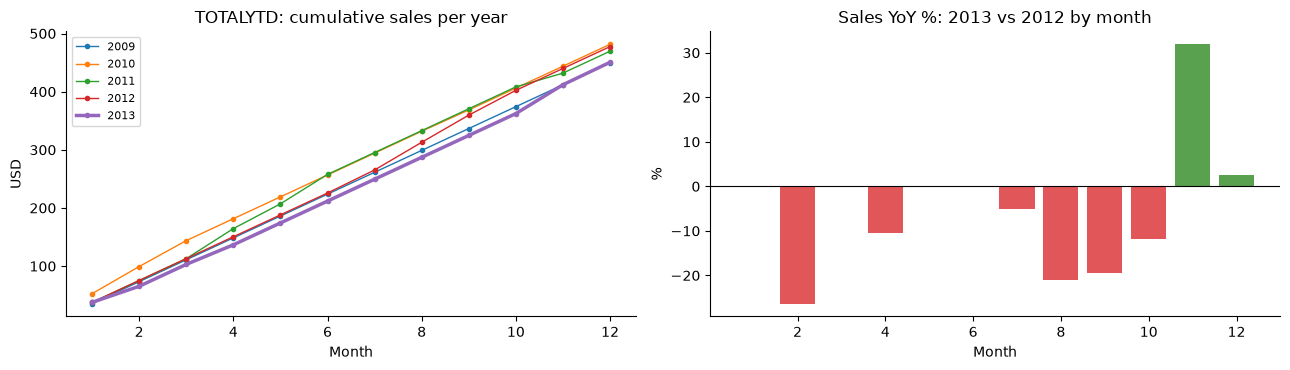

In [5]:
monthly = model.groupby(["Year", "Month"])["Amount"].sum().unstack("Year").reindex(range(1, 13))
ytd = monthly.cumsum()
latest = monthly.columns.max()
yoy = (monthly[latest] - monthly[latest - 1]) / monthly[latest - 1]
answer = pd.DataFrame({f"Sales {latest}": monthly[latest], f"Sales LY ({latest - 1})": monthly[latest - 1],
                       "YoY %": (100 * yoy).round(1), f"Sales YTD {latest}": ytd[latest]}).round(2)
print(answer.head(6))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
for y in monthly.columns:
    ax1.plot(ytd.index, ytd[y], marker=".", lw=2.5 if y == latest else 1, label=str(y))
ax1.set(title="TOTALYTD: cumulative sales per year", xlabel="Month", ylabel="USD")
ax1.legend(fontsize=8)
ax2.bar(yoy.index, 100 * yoy, color=np.where(yoy >= 0, "#59A14F", "#E15759"))
ax2.axhline(0, color="black", lw=0.8)
ax2.set(title=f"Sales YoY %: {latest} vs {latest - 1} by month", xlabel="Month", ylabel="%")
plt.tight_layout()
plt.show()

## 5. Power BI vs Tableau, and the Free Path

| | Power BI Desktop | Tableau Public |
| :--- | :--- | :--- |
| cost to author | free (Windows) | free (Windows, macOS) |
| sharing | Power BI service licence (or a Fabric capacity) | public website only (no private data) |
| transform | Power Query (M) | Tableau Prep (separate) or calculated fields |
| model | star schema, relationships, DAX | relationships, LOD expressions |
| strength | Microsoft ecosystem, DAX modelling | visual exploration, design flexibility |

**Exercise:** load the four CSV files into Power BI Desktop, create the relationships of Section 2 and the measures of Sections 3–4, and compare your matrix with the answer key above.

*Insight: In Power BI, put the business logic in measures, not in calculated columns, and think in filter context: every cell of a visual evaluates the measure with its own filters, and `CALCULATE` is the tool to change them.*

## Real-World Use Case or Analogy

Filter context is like a **spreadsheet that recalculates each cell with its own question**: the cell for "Brazil, 2024" asks "total sales where country = Brazil and year = 2024", the total cell asks the same question without any country. `CALCULATE` lets a cell ask a modified question, for example "and ignore the country" for a percent-of-total.

Power BI is the most common BI tool in companies that use Microsoft 365; job descriptions for data and business analysts frequently ask for DAX and Power Query skills.